<a href="https://colab.research.google.com/github/ruhailarshad/programming_assignment/blob/main/career_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_excel("/content/sample_data/Career data_PDA_4053.xlsx")

In [6]:
df.head()
df.info()
df.describe()
df.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Field of Study               4999 non-null   object 
 1   Current Occupation           4996 non-null   object 
 2   Age                          4996 non-null   float64
 3   Gender                       4993 non-null   object 
 4   Years of Experience          4998 non-null   float64
 5   Education Level              4994 non-null   object 
 6   Industry Growth Rate         4995 non-null   object 
 7   Job Satisfaction             4998 non-null   float64
 8   Work-Life Balance            4997 non-null   float64
 9   Job Opportunities            4993 non-null   float64
 10  Salary                       4994 non-null   object 
 11  Job Security                 4996 non-null   float64
 12  Career Change Interest       4995 non-null   object 
 13  Skills Gap        

,0
Field of Study,1
Current Occupation,4
Age,4
Gender,7
Years of Experience,2
Education Level,6
Industry Growth Rate,5
Job Satisfaction,2
Work-Life Balance,3
Job Opportunities,7


In [7]:
df_clean = df.copy()
df_clean['Salary'] = pd.to_numeric(df_clean['Salary'], errors='coerce')

In [8]:
df_clean.loc[df_clean['Career Change Interest'] == 'A', 'Career Change Interest'] = np.nan
df_clean['Career Change Interest'] = df_clean['Career Change Interest'].astype('float64')


In [9]:
df_clean.isna().sum()


,0
Field of Study,1
Current Occupation,4
Age,4
Gender,7
Years of Experience,2
Education Level,6
Industry Growth Rate,5
Job Satisfaction,2
Work-Life Balance,3
Job Opportunities,7


In [10]:
num_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df_clean.select_dtypes(include=['object']).columns

# numeric columns with median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# categorical columns with mode
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean.isna().sum().sum()

np.int64(0)

In [11]:
def outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((s < lower) | (s > upper)).sum(), lower, upper

for col in ['Age', 'Years of Experience', 'Salary', 'Job Opportunities']:
    count, lower, upper = outliers(df_clean[col])
    print(col, "outliers:", count, "bounds:", (lower, upper))


Age outliers: 0 bounds: (-1.0, 79.0)
Years of Experience outliers: 0 bounds: (-20.0, 60.0)
Salary outliers: 6 bounds: (-53408.875, 285130.125)
Job Opportunities outliers: 0 bounds: (-51.5, 152.5)


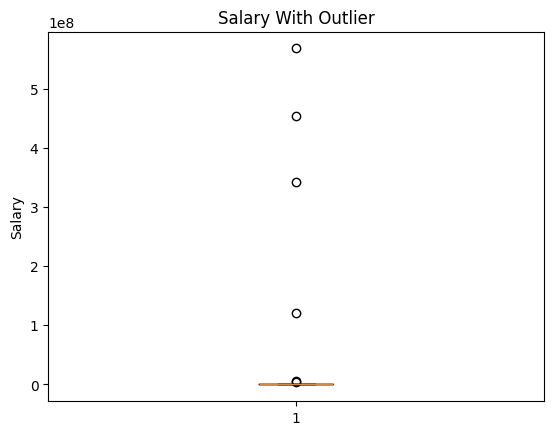

In [12]:
plt.boxplot(df_clean['Salary'].dropna())
plt.title("Salary With Outlier")
plt.ylabel("Salary")
plt.show()


In [13]:
df_clean_copy = df_clean.copy()

col = 'Salary'
q1, q3 = df_clean_copy[col].quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

before_outliers = ((df_clean_copy[col] < lower) | (df_clean_copy[col] > upper)).sum()

df_clean_copy[col] = np.where(df_clean_copy[col] > upper, upper,
                      np.where(df_clean_copy[col] < lower, lower, df_clean_copy[col]))

after_outliers = ((df_clean_copy[col] < lower) | (df_clean_copy[col] > upper)).sum()
print("Outliers before:", before_outliers, "after:", after_outliers)


Outliers before: 6 after: 0


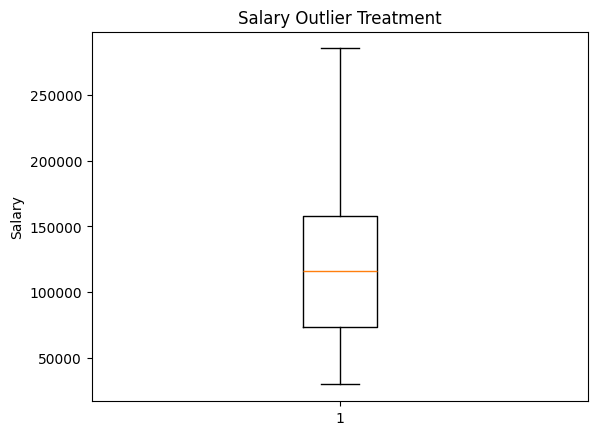

In [14]:
plt.boxplot(df_clean_copy['Salary'])
plt.title("Salary Outlier Treatment")
plt.ylabel("Salary")
plt.show()


In [15]:
raw_summary = df[['Age', 'Years of Experience', 'Salary',
                  'Job Satisfaction', 'Job Opportunities',
                  'Likely to Change Occupation']].copy()
raw_summary['Salary'] = pd.to_numeric(raw_summary['Salary'], errors='coerce')
raw_stats = raw_summary.describe()

clean_sumary = df_clean_copy[['Age', 'Years of Experience', 'Salary',
                       'Job Satisfaction', 'Job Opportunities',
                       'Likely to Change Occupation']]
clean_stats = clean_sumary.describe()

print("Raw stats:\n", raw_stats)
print("\nCleaned stats:\n", clean_stats)


Raw stats:
                Age  Years of Experience        Salary  Job Satisfaction  \
count  4996.000000          4998.000000  4.993000e+03       4998.000000   
mean     39.364892            19.774310  4.152932e+05          5.496399   
std      11.457086            11.527082  1.149769e+07          2.895880   
min      20.000000             0.000000  3.001600e+04          1.000000   
25%      29.000000            10.000000  7.344100e+04          3.000000   
50%      40.000000            20.000000  1.164240e+05          6.000000   
75%      49.000000            30.000000  1.582090e+05          8.000000   
max      59.000000            39.000000  5.678965e+08         10.000000   

       Job Opportunities  Likely to Change Occupation  
count        4993.000000                  4999.000000  
mean           50.622672                     0.570714  
std            29.025295                     0.495024  
min             1.000000                     0.000000  
25%            25.000000        

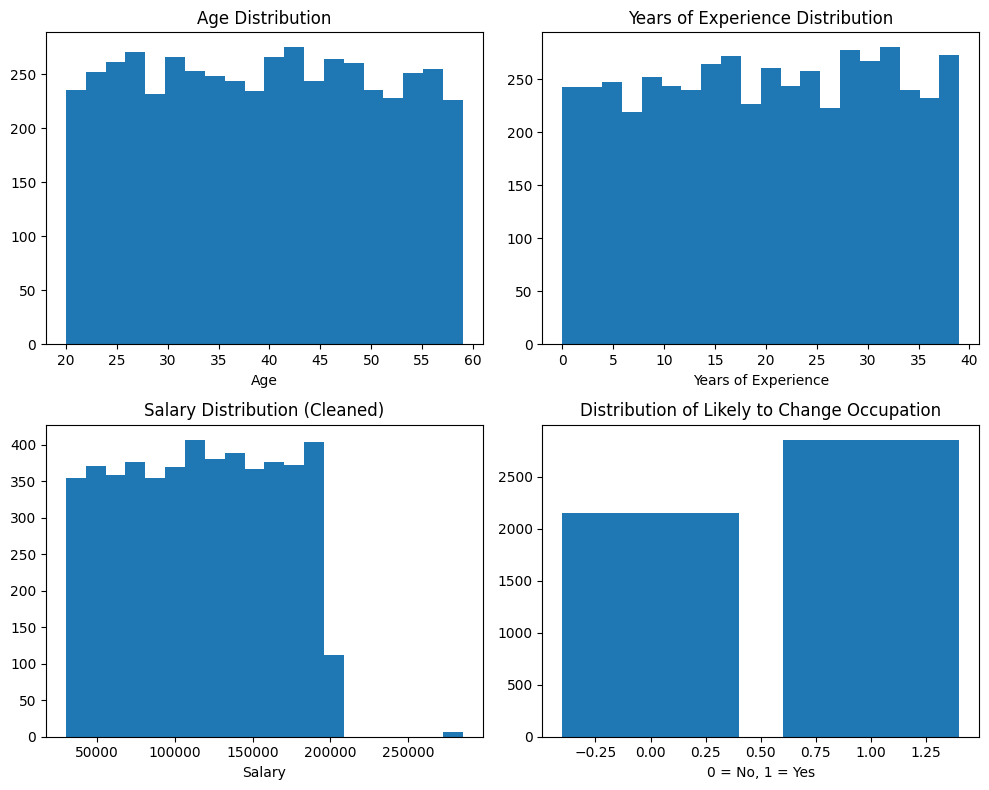

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Age
axes[0,0].hist(df_clean_copy['Age'], bins=20)
axes[0,0].set_title("Age Distribution")
axes[0,0].set_xlabel("Age")

# Years of Experience
axes[0,1].hist(df_clean_copy['Years of Experience'], bins=20)
axes[0,1].set_title("Years of Experience Distribution")
axes[0,1].set_xlabel("Years of Experience")

# Salary
axes[1,0].hist(df_clean_copy['Salary'], bins=20)
axes[1,0].set_title("Salary Distribution (Cleaned)")
axes[1,0].set_xlabel("Salary")

# Likely to Change Occupation
counts = df_clean_copy['Likely to Change Occupation'].value_counts()
axes[1,1].bar(counts.index, counts.values)
axes[1,1].set_title("Distribution of Likely to Change Occupation")
axes[1,1].set_xlabel("0 = No, 1 = Yes")

plt.tight_layout()
plt.show()

In [19]:
edu_change = pd.crosstab(df_clean_copy['Education Level'],
                         df_clean_copy['Likely to Change Occupation'],
                         normalize='index') * 100
print(edu_change)


Likely to Change Occupation        0.0        1.0
Education Level                                  
Bachelor's                   42.353883  57.646117
High School                  42.676168  57.323832
Master's                     42.351047  57.648953
PhD                          44.301766  55.698234


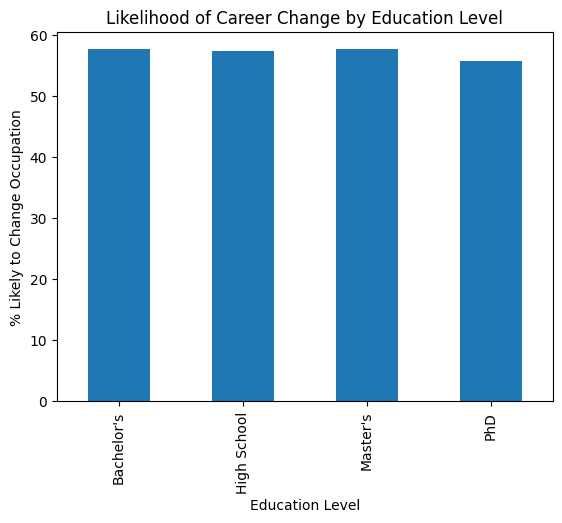

In [20]:
edu_change[1.0].plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likelihood of Career Change by Education Level")
plt.show()


Likely to Change Occupation        0.0        1.0
Field of Study                                   
Computer Science             46.639511  53.360489
Arts                         44.602851  55.397149
Economics                    44.583333  55.416667
Business                     43.502825  56.497175
Biology                      43.204868  56.795132
Psychology                   43.186583  56.813417
Education                    42.585551  57.414449
Medicine                     41.825095  58.174905
Mechanical Engineering       40.393013  59.606987
Law                          38.899431  61.100569


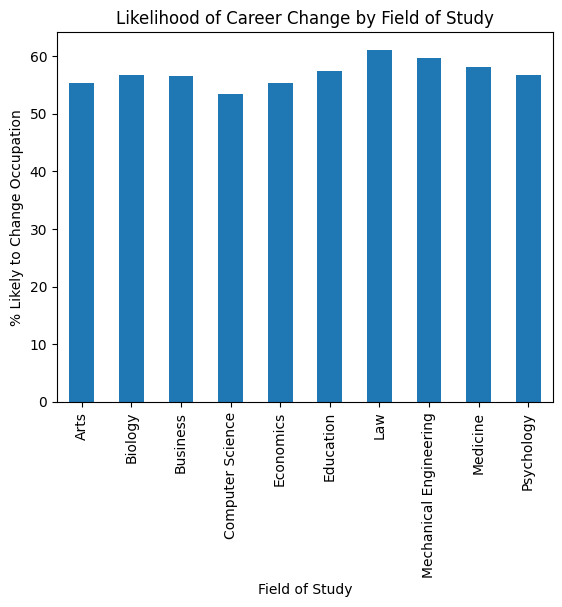

In [22]:
field_change = pd.crosstab(df_clean_copy['Field of Study'],
                           df_clean_copy['Likely to Change Occupation'],
                           normalize='index') * 100
print(field_change.sort_values(1.0))
field_change[1.0].plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likelihood of Career Change by Field of Study")
plt.show()


Experience_band
0-5      55.677155
6-10     59.228188
11-20    57.050766
21-30    55.748031
31-40    58.347676
Name: Likely to Change Occupation, dtype: float64
Age_band
20-25    59.358289
26-35    55.984252
36-45    56.294537
46-55    57.512116
56-59    57.380457
Name: Likely to Change Occupation, dtype: float64


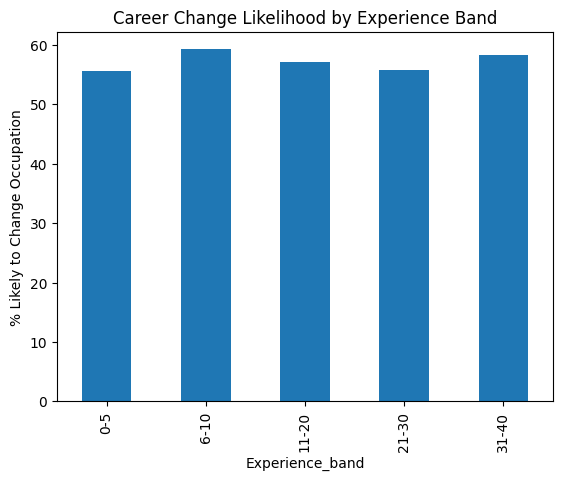

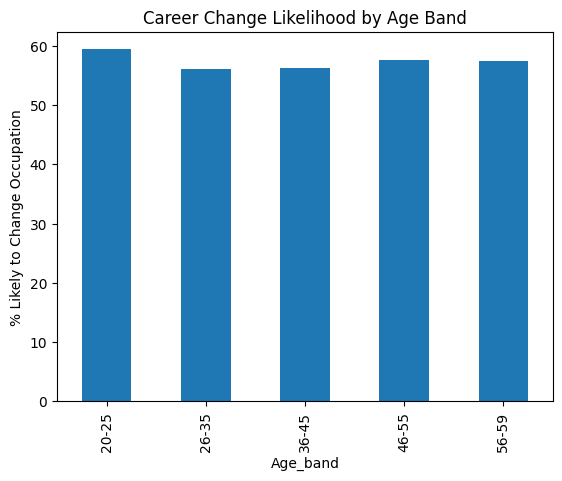

In [26]:
df_clean_copy['Experience_band'] = pd.cut(df_clean_copy['Years of Experience'],
                                  bins=[-0.1, 5, 10, 20, 30, 40],
                                  labels=['0-5', '6-10', '11-20', '21-30', '31-40'])

df_clean_copy['Age_band'] = pd.cut(df_clean_copy['Age'],
                           bins=[19, 25, 35, 45, 55, 60],
                           labels=['20-25', '26-35', '36-45', '46-55', '56-59'])

exp_change = df_clean_copy.groupby('Experience_band', observed=False)['Likely to Change Occupation'].mean() * 100
age_change = df_clean_copy.groupby('Age_band', observed=False)['Likely to Change Occupation'].mean() * 100

print(exp_change)
print(age_change)

exp_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Career Change Likelihood by Experience Band")
plt.show()

age_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Career Change Likelihood by Age Band")
plt.show()

Sat_band
Low       100.000000
Medium     45.837513
High       28.980680
Name: Likely to Change Occupation, dtype: float64
WLB_band
Low       57.340355
Medium    58.841779
High      54.621849
Name: Likely to Change Occupation, dtype: float64


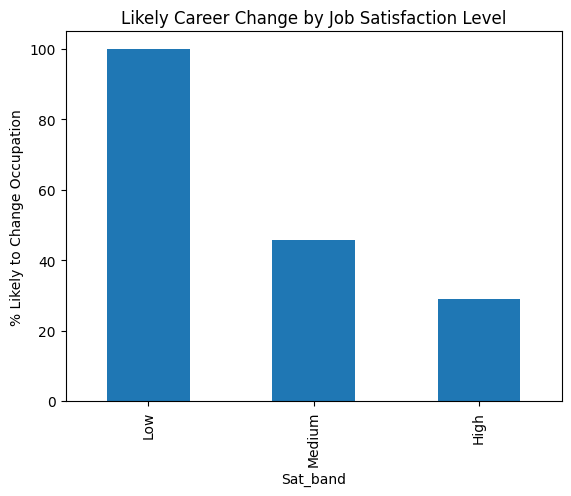

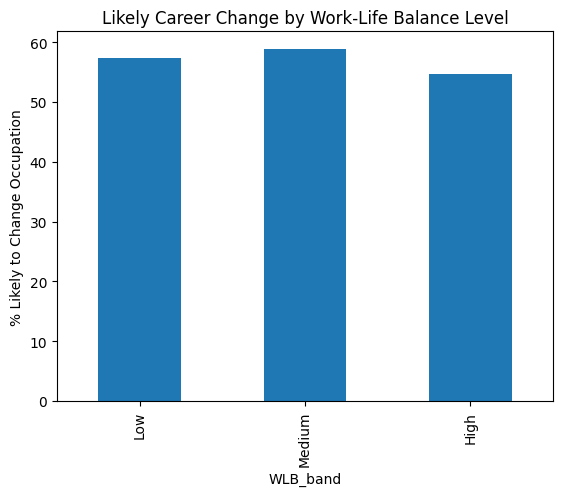

In [29]:
df_clean_copy['Sat_band'] = pd.cut(df_clean_copy['Job Satisfaction'],
                           bins=[0, 3, 7, 10],
                           labels=['Low', 'Medium', 'High'])
df_clean_copy['WLB_band'] = pd.cut(df_clean_copy['Work-Life Balance'],
                           bins=[0, 3, 7, 10],
                           labels=['Low', 'Medium', 'High'])

sat_change = df_clean_copy.groupby('Sat_band',observed=False)['Likely to Change Occupation'].mean() * 100
wlb_change = df_clean_copy.groupby('WLB_band',observed=False)['Likely to Change Occupation'].mean() * 100

print(sat_change)
print(wlb_change)

sat_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likely Career Change by Job Satisfaction Level")
plt.show()

wlb_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likely Career Change by Work-Life Balance Level")
plt.show()


Sat_band
Low       100.000000
Medium     45.837513
High       28.980680
Name: Likely to Change Occupation, dtype: float64
WLB_band
Low       57.340355
Medium    58.841779
High      54.621849
Name: Likely to Change Occupation, dtype: float64


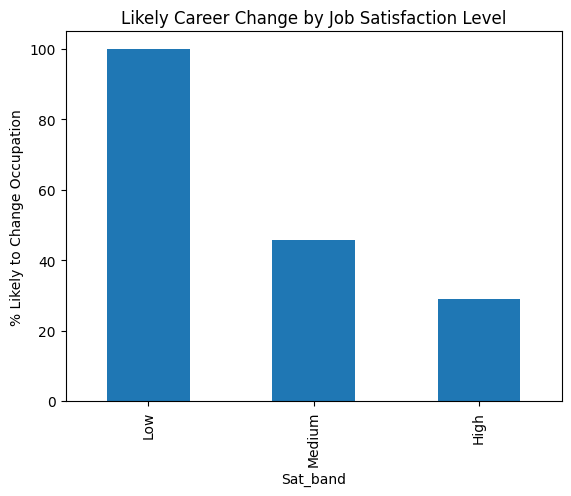

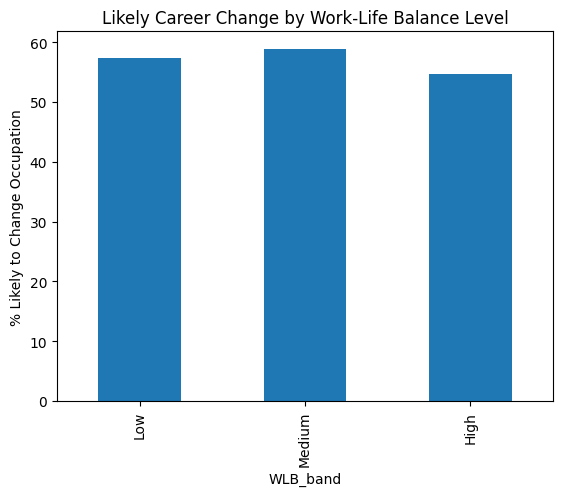

In [30]:
df_clean_copy['Sat_band'] = pd.cut(df_clean_copy['Job Satisfaction'],
                           bins=[0, 3, 7, 10],
                           labels=['Low', 'Medium', 'High'])
df_clean_copy['WLB_band'] = pd.cut(df_clean_copy['Work-Life Balance'],
                           bins=[0, 3, 7, 10],
                           labels=['Low', 'Medium', 'High'])

sat_change = df_clean_copy.groupby('Sat_band',observed=False)['Likely to Change Occupation'].mean() * 100
wlb_change = df_clean_copy.groupby('WLB_band',observed=False)['Likely to Change Occupation'].mean() * 100

print(sat_change)
print(wlb_change)

sat_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likely Career Change by Job Satisfaction Level")
plt.show()

wlb_change.plot(kind='bar')
plt.ylabel("% Likely to Change Occupation")
plt.title("Likely Career Change by Work-Life Balance Level")
plt.show()



In [33]:
interest_change = df_clean_copy.groupby('Career Change Interest')['Likely to Change Occupation'].mean() * 100
print(interest_change)


Career Change Interest
0.0     46.470442
1.0    100.000000
Name: Likely to Change Occupation, dtype: float64
